# Asynchronous jobs and scheduling

Real QPUs are shared, so jobs wait. QPUTwin behaves the same way: an asynchronous job is stored durably, queued, and
dispatched as a slot frees. Each twin here has one dispatch slot, like a single QPU.

In [1]:
from qputwin_demo import *

connect();

QPUTwin at http://localhost:8000: ready, 7 twins reachable


## Submit, then collect

The server answers `202 Accepted` immediately with a job id. `wait` long-polls until the job finishes.

In [2]:
accepted = submit("ionq_forte", ghz(8), seed=11)
print({key: accepted[key] for key in ("job_id", "status", "queue_position", "links")})

finished = job(accepted["job_id"], wait=10)
print("Final status:", finished["status"], "| Attempts:", finished["attempts"])
print("Counts:", finished["result"]["counts"])

{'job_id': 'b09a859d29a445c999f24540ece8cca6', 'status': 'QUEUED', 'queue_position': 1, 'links': {'self': '/v1/jobs/b09a859d29a445c999f24540ece8cca6'}}
Final status: COMPLETED | Attempts: 1
Counts: {'00000000': 532, '11111111': 492}


A finished asynchronous job has the same body as a synchronous one, and the same seed gives the same counts.

In [3]:
synchronous = run("ionq_forte", ghz(8), seed=11)
print("Identical counts:", synchronous["result"]["counts"] == finished["result"]["counts"])

Identical counts: True


## Watching a queue

Thirty jobs arrive at once on one twin, so a queue forms and then drains at the speed of the single slot.

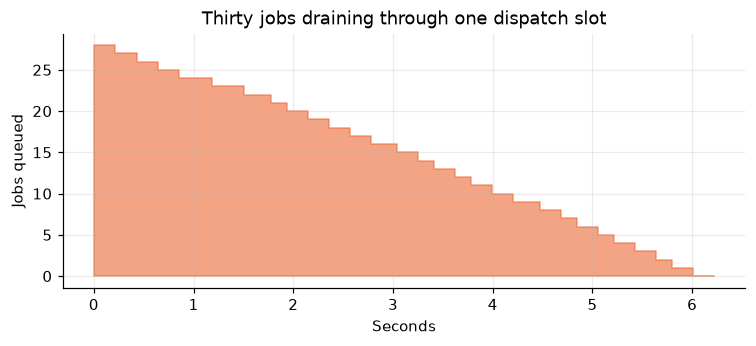

Completed: 30 of 30
Throughput: 4.8 jobs/s


In [4]:
heavy = scrambler(22, 6)
ids = [submit("ionq_forte", heavy, seed=i, shots=256)["job_id"] for i in range(30)]

timeline = []
start = time.time()
while True:
    state = queues()["ionq_forte"]
    timeline.append((time.time() - start, state["queued"], state["running"]))
    if state["queued"] + state["running"] == 0:
        break
    time.sleep(0.05)
timeline = pd.DataFrame(timeline, columns=["t", "queued", "running"])

fig, ax = plt.subplots(figsize=(8, 3))
ax.fill_between(timeline.t, timeline.queued, step="post", color=COLORS["ionq_forte"], alpha=0.6)
ax.set(xlabel="Seconds", ylabel="Jobs queued", title="Thirty jobs draining through one dispatch slot")
plt.show()

done = [job(i) for i in ids]
print("Completed:", sum(j["status"] == "COMPLETED" for j in done), "of", len(done))
print(f"Throughput: {len(done) / timeline.t.iloc[-1]:.1f} jobs/s")

## Priority

A long job holds the slot while ten more arrive, half at low priority and half at high. Priority 9 jobs run first, even
though they were submitted last.

In [5]:
blocker = submit("ionq_forte", heavy, seed=100, shots=256)
low = [submit("ionq_forte", ghz(10), seed=i, priority=1)["job_id"] for i in range(5)]
high = [submit("ionq_forte", ghz(10), seed=i, priority=9)["job_id"] for i in range(5)]

rows = [{"priority": priority, "started": job(i, wait=30)["started_at"]} for priority, group in ((1, low), (9, high)) for i in group]
order = pd.DataFrame(rows).sort_values("started").reset_index(drop=True)
order["run order"] = order.index + 1
order[["run order", "priority"]].set_index("run order").T

run order,1,2,3,4,5,6,7,8,9,10
priority,9,9,9,9,9,1,1,1,1,1


## Cancelling

A queued job can be cancelled before it runs.

In [6]:
blocker = submit("ionq_forte", heavy, seed=200, shots=256)
queued = submit("ionq_forte", ghz(10), seed=201)
print("Cancel returned:", cancel(queued["job_id"])["status"])
print("Status now:     ", job(queued["job_id"])["status"])
job(blocker["job_id"], wait=30);

Cancel returned: CANCELLED
Status now:      CANCELLED


## Fair share

One client floods a twin with sixty jobs, then a second client sends one job at a time. With first-come-first-served,
that client would wait behind the whole backlog. The claim order prefers the client served least recently, so it waits
for about one running job. Clients are named here with the `x-qputwin-client` header; with authentication on, the API
key identifies them.

In [7]:
flood = [submit("ionq_forte", heavy, client="flooder", seed=i, shots=256)["job_id"] for i in range(60)]
time.sleep(0.5)

light = []
for i in range(6):
    backlog = queues()["ionq_forte"]["queued"]
    start = time.time()
    finished = job(submit("ionq_forte", ghz(8), client="light-user", seed=i)["job_id"], wait=30)
    light.append({"Backlog when submitted": backlog, "Light client's total time (s)": round(time.time() - start, 3)})
pd.DataFrame(light)

,Backlog when submitted,Light client's total time (s)
0,54,0.148
1,53,0.239
2,52,0.190
3,51,0.190
4,50,0.190
5,49,0.239


In [8]:
single = pd.Series([job(i, wait=30)["telemetry"]["breakdown"]["worker_service_ms"] for i in flood[:10]]).median() / 1000
total = pd.DataFrame(light)
print(f"One flood job takes about {single:.3f} s.")
print(f"Without fair share, a backlog of {total.iloc[0, 0]} jobs would mean a wait of about {total.iloc[0, 0] * single:.1f} s.")
print(f"The light client actually took {total.iloc[:, 1].median():.3f} s (median).")

for i in flood:
    job(i, wait=30)
print("Flood drained:", queues()["ionq_forte"])

One flood job takes about 0.200 s.
Without fair share, a backlog of 54 jobs would mean a wait of about 10.8 s.
The light client actually took 0.190 s (median).


Flood drained: {'queued': 0, 'running': 0, 'capacity': 1}


Notebook 08 shows the other half of this service: jobs surviving a crash.